# Chapitre 3 - Cours 2 : sélection de variables, ridge et lasso

Ce notebook couvre les sections 3.3 et 3.4 du livre. Les moindres carrés ont deux défauts :

- **précision de prédiction** : ils sont sans biais mais souvent de grande variance ; en
  annulant ou en rétrécissant certains coefficients, on accepte un peu de biais pour
  réduire la variance (cf. cours 1, §5) ;
- **interprétation** : avec beaucoup de prédicteurs, on préfère un petit sous-ensemble aux
  effets les plus forts.

Deux familles de remèdes sont étudiées ici, toujours sur les données de la prostate :

1. la **sélection de sous-ensembles** : meilleur sous-ensemble, pas à pas ascendant et
   descendant, régression « stagewise » ;
2. les méthodes de **rétrécissement** (*shrinkage*) : régression **ridge** et **lasso**.

Nous reproduisons les figures 3.5, 3.8, 3.10, 3.11, 3.12 et les panneaux correspondants de
la figure 3.7 (courbes de validation croisée).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

import pandas as pd
from sklearn.linear_model import Lasso, Ridge
from esl import ch03_regression as cr

pd.set_option("display.precision", 3)


def label_ends(ax, x, values, labels, gap=0.035):
    """Écrit les noms des variables au bout des profils en évitant les chevauchements."""
    order = np.argsort(values)
    pos = np.array(values, float)[order]
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + gap)
    for k, j in enumerate(order):
        ax.text(x, pos[k], labels[j], color=COLORS[j], fontsize=8, va="center")

Données de la prostate standardisées (comme au cours 1) : 67 observations
d'apprentissage, 30 de test, 8 prédicteurs.

In [2]:
Xtr, ytr, Xte, yte, names = cr.load_prostate_standardized()
N, p = Xtr.shape
fit_ls = cr.ols_fit(Xtr, ytr)


def test_error(b0, beta):
    """Erreur quadratique moyenne sur l'échantillon de test."""
    return np.mean((yte - b0 - Xte @ beta) ** 2)


print("moindres carrés : erreur de test = %.3f" % test_error(fit_ls["coef"][0], fit_ls["coef"][1:]))

moindres carrés : erreur de test = 0.521


## 1. Sélection du meilleur sous-ensemble

Pour chaque taille $k \in \{0, 1, \dots, p\}$, la **sélection du meilleur sous-ensemble**
(*best subset*) cherche le sous-ensemble de $k$ variables dont la régression par moindres
carrés a le plus petit RSS. Avec $p = 8$, il n'y a que $2^8 = 256$ sous-ensembles : on
peut tous les essayer. (Pour $p$ jusqu'à 30 ou 40, l'algorithme *leaps and bounds* évite
l'énumération complète ; au-delà, c'est impraticable.)

In [3]:
all_rss = cr.all_subsets_rss(Xtr, ytr)
subsets, best_rss = cr.best_subset(Xtr, ytr)
print("nombre de sous-ensembles :", len(all_rss))
pd.DataFrame({"meilleur sous-ensemble": [", ".join(names[j] for j in S) or "(constante)" for S in subsets],
              "RSS": best_rss}, index=pd.Index(range(p + 1), name="k"))

nombre de sous-ensembles : 256


,meilleur sous-ensemble,RSS
k,,
0,(constante),96.281
1,lcavol,44.529
2,"lcavol, lweight",37.092
3,"lcavol, lweight, svi",34.908
4,"lcavol, lweight, lbph, svi",32.815
5,"lcavol, lweight, lbph, svi, pgg45",32.069
6,"lcavol, lweight, lbph, svi, lcp, pgg45",30.540
7,"lcavol, lweight, age, lbph, svi, lcp, pgg45",29.437
8,"lcavol, lweight, age, lbph, svi, lcp, gleason,...",29.426


La figure 3.5 du livre montre le RSS de **tous** les sous-ensembles, rangés par taille ;
la frontière inférieure (en orange) est formée des meilleurs sous-ensembles.

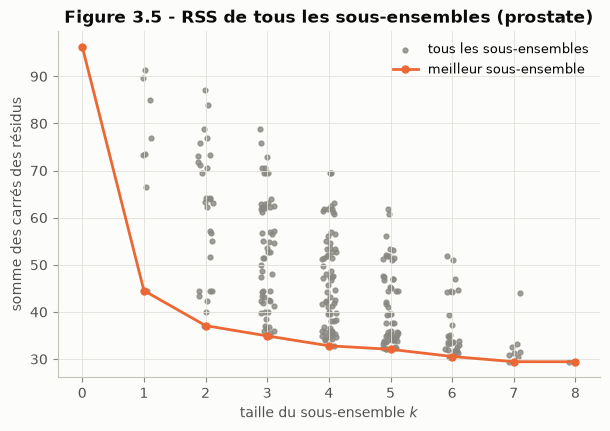

In [4]:
rng = np.random.RandomState(0)
ks = np.array([len(S) for S, _ in all_rss])
rs = np.array([r for _, r in all_rss])
fig, ax = plt.subplots()
ax.scatter(ks + rng.uniform(-0.12, 0.12, len(ks)), rs, s=12, color=GRAY, alpha=0.8,
           label="tous les sous-ensembles")
ax.plot(range(p + 1), best_rss, "o-", color=ORANGE, label="meilleur sous-ensemble")
ax.set_title("Figure 3.5 - RSS de tous les sous-ensembles (prostate)")
ax.set_xlabel("taille du sous-ensemble $k$"); ax.set_ylabel("somme des carrés des résidus")
ax.legend()
plt.show()

Ici les meilleurs sous-ensembles sont **emboîtés** (chacun contient le précédent), mais ce
n'est pas garanti en général. Surtout, la courbe des meilleurs RSS est **décroissante** :
plus de variables, meilleur ajustement sur l'apprentissage. Elle ne peut donc pas servir à
choisir $k$ ; il faut un critère qui estime l'**erreur de prédiction** sur de nouvelles
données.

## 2. Choisir la complexité : la validation croisée

La plupart des méthodes de ce chapitre produisent une **famille de modèles** indexée par
un paramètre de complexité ($k$, $\lambda$, $s$, $M$…). Pour choisir ce paramètre, on
utilise ici la **validation croisée à $K = 10$ plis** (détaillée au chapitre 7) :

1. on partage aléatoirement les $N$ observations d'apprentissage en $K$ parts égales ;
2. pour chaque part $\kappa$, on ajuste toute la famille sur les $K-1$ autres parts et
   l'on calcule l'erreur quadratique moyenne $e_\kappa$ sur la part $\kappa$ ;
3. l'erreur estimée est $\mathrm{CV} = \frac{1}{K}\sum_{\kappa} e_\kappa$, avec l'erreur
   standard $\mathrm{se} = \mathrm{sd}(e_1, \dots, e_K)/\sqrt{K}$.

**Règle « un écart-type ».** Les courbes de validation croisée sont souvent très plates
près de leur minimum, et elles sont estimées avec erreur. On retient donc le modèle **le
plus simple** dont l'erreur CV est inférieure à $\mathrm{CV}_{\min} + \mathrm{se}_{\min}$
(minimum plus son erreur standard).

> **Remarque.** Le résultat dépend du découpage aléatoire en plis. Nous fixons un découpage
> (graine 12, qui donne des choix proches de ceux du livre) et l'utilisons pour **toutes**
> les méthodes ; la variabilité due au découpage est étudiée dans le cours 3.

In [5]:
folds = cr.kfold_indices(N, K=10, rng=np.random.RandomState(12))
print("tailles des plis :", [len(f) for f in folds])


def plot_cv(ax, grid, mean, se, title, xlabel):
    """Courbe de validation croisée avec barres d'erreur et choix « un écart-type »."""
    i_best = cr.one_se_rule(mean, se)
    ax.errorbar(grid, mean, yerr=se, fmt="o-", color=ORANGE, ecolor=BLUE,
                capsize=3, markersize=4, linewidth=1.5)
    ax.axhline(mean.min() + se[np.argmin(mean)], color=GRAY, linestyle=":", linewidth=1)
    ax.axvline(grid[i_best], color=COLORS[6], linestyle="--", linewidth=1)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("erreur de validation croisée")
    ax.set_ylim(0.3, 1.8)
    return i_best

tailles des plis : [7, 7, 7, 7, 7, 7, 7, 6, 6, 6]


Panneau « All Subsets » de la figure 3.7 : erreur CV du meilleur sous-ensemble en
fonction de sa taille.

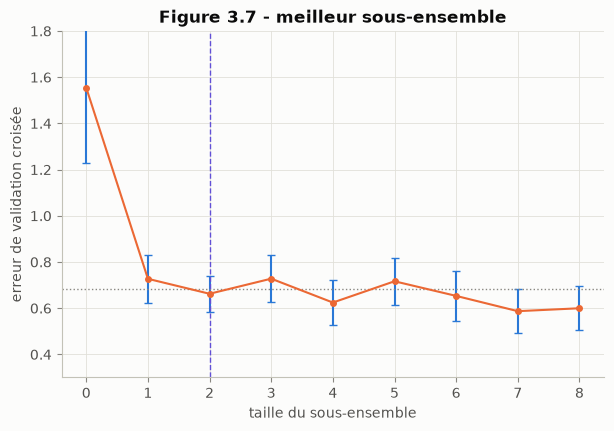

taille retenue par la règle un écart-type : 2 -> ['lcavol', 'lweight']


In [6]:
cv_bs, se_bs = cr.cv_error(cr.best_subset_path, Xtr, ytr, folds)
fig, ax = plt.subplots()
k_bs = plot_cv(ax, np.arange(p + 1), cv_bs, se_bs, "Figure 3.7 - meilleur sous-ensemble",
               "taille du sous-ensemble")
plt.show()
print("taille retenue par la règle un écart-type :", k_bs, "->", [names[j] for j in subsets[k_bs]])

Comme dans le livre, la règle retient les **deux** prédicteurs `lcavol` et `lweight`.
Le pointillé horizontal marque le seuil $\mathrm{CV}_{\min} + \mathrm{se}_{\min}$, le tireté
vertical le modèle choisi.

In [7]:
b0_bs, B_bs = cr.best_subset_path(Xtr, ytr)
print("coefficients :", dict(zip(["intercept"] + names, np.r_[b0_bs[k_bs], B_bs[k_bs]].round(3))))
print("erreur de test : %.3f" % test_error(b0_bs[k_bs], B_bs[k_bs]))

coefficients : {'intercept': np.float64(2.477), 'lcavol': np.float64(0.74), 'lweight': np.float64(0.316), 'age': np.float64(0.0), 'lbph': np.float64(0.0), 'svi': np.float64(0.0), 'lcp': np.float64(0.0), 'gleason': np.float64(0.0), 'pgg45': np.float64(0.0)}
erreur de test : 0.492


## 3. Sélection pas à pas

### 3.1 Pas à pas ascendante (*forward stepwise*)

Au lieu d'explorer tous les sous-ensembles, on construit un **chemin** : on part de la
constante seule, puis on ajoute à chaque étape la variable qui **diminue le plus le RSS**.
C'est un algorithme **glouton**, qui produit une suite de modèles emboîtés.

Avantages : coût faible (possible même si $p \gg N$), et recherche plus contrainte, donc
**moins de variance** que le meilleur sous-ensemble (au prix d'un peu de biais).

**Mise à jour efficace (exercice 3.9).** Soit $\mathbf{Q}$ une base orthonormée des
variables déjà retenues (constante incluse) et $\mathbf{r}$ le résidu courant. Pour une
candidate $\mathbf{x}_j$, notons $\mathbf{e}_j = \mathbf{x}_j - \mathbf{Q}\mathbf{Q}^T\mathbf{x}_j$
sa partie orthogonale aux variables retenues. L'ajouter revient à projeter $\mathbf{r}$ sur
$\mathbf{e}_j$, ce qui diminue le RSS de

$$
\Delta_j = \frac{\langle \mathbf{e}_j, \mathbf{r}\rangle^2}{\lVert\mathbf{e}_j\rVert^2}.
$$

On choisit le $j$ qui maximise $\Delta_j$, puis on ajoute $\mathbf{e}_j/\lVert\mathbf{e}_j\rVert$
à $\mathbf{Q}$ (une étape de Gram–Schmidt).

In [8]:
order_fw, rss_fw = cr.forward_stepwise(Xtr, ytr)
print("ordre d'entrée :", [names[j] for j in order_fw])
print("RSS            :", rss_fw.round(2))

ordre d'entrée : ['lcavol', 'lweight', 'svi', 'lbph', 'pgg45', 'lcp', 'age', 'gleason']
RSS            : [96.28 44.53 37.09 34.91 32.81 32.07 30.54 29.44 29.43]


### 3.2 Pas à pas descendante (*backward stepwise*)

On part du modèle complet et l'on retire à chaque étape la variable dont le retrait
**augmente le moins le RSS**. D'après l'exercice 3.1, cette hausse vaut
$z_j^2\,\hat\sigma^2$ : on retire la variable de plus petit $|z_j|$ (exercice 3.10). Cette
méthode exige $N > p$.

In [9]:
removed_bw, rss_bw = cr.backward_stepwise(Xtr, ytr)
print("ordre de retrait :", [names[j] for j in removed_bw])
print("ordre d'entrée équivalent :", [names[j] for j in removed_bw[::-1]])

ordre de retrait : ['gleason', 'age', 'lcp', 'pgg45', 'lbph', 'svi', 'lweight', 'lcavol']
ordre d'entrée équivalent : ['lcavol', 'lweight', 'svi', 'lbph', 'pgg45', 'lcp', 'age', 'gleason']


Sur la prostate, meilleur sous-ensemble, pas à pas ascendante et descendante donnent
**exactement la même suite** de modèles (comme le signale le livre) :

In [10]:
same = all(set(subsets[k]) == set(order_fw[:k]) == set(removed_bw[::-1][:k]) for k in range(p + 1))
print("mêmes sous-ensembles pour chaque k ?", same)

mêmes sous-ensembles pour chaque k ? True


> **Attention.** Après une recherche de modèle, les erreurs standard affichées par une
> régression (comme au tableau 3.2) ne sont **plus valides** : elles ignorent que les
> variables ont été choisies au vu des données. Le bootstrap (chapitre 8) peut aider.

### 3.3 Régression « stagewise » ascendante (*forward stagewise*)

Encore plus contrainte : on part de $\beta = 0$ (constante $\bar y$, prédicteurs centrés).
À chaque étape :

1. on cherche la variable $\mathbf{x}_j$ la plus corrélée au résidu courant $\mathbf{r}$ ;
2. on ajoute à $\beta_j$ le coefficient de la régression **simple** de $\mathbf{r}$ sur
   $\mathbf{x}_j$, soit $\langle\mathbf{x}_j, \mathbf{r}\rangle/\lVert\mathbf{x}_j\rVert^2$ ;
3. on met à jour $\mathbf{r}$.

Contrairement au pas à pas, les **autres coefficients ne sont pas réajustés** : il faut
souvent beaucoup plus de $p$ étapes pour atteindre les moindres carrés.

In [ ]:
path_fs = cr.forward_stagewise(Xtr, ytr, n_steps=400)
print("nombre d'étapes effectuées :", len(path_fs) - 1)
print("écart final aux moindres carrés : %.2e" % np.abs(path_fs[-1] - fit_ls["coef"][1:]).max())

In [ ]:
fig, ax = plt.subplots()
for j in range(p):
    ax.plot(path_fs[:, j], color=COLORS[j], label=names[j], linewidth=1.5)
ax.set_xscale("symlog", linthresh=10)
ax.set_title("Régression stagewise : coefficients au fil des étapes")
ax.set_xlabel("étape (échelle log au-delà de 10)"); ax.set_ylabel(r"coefficient $\hat\beta_j$")
ax.legend(ncol=2)
plt.show()